<a href="https://colab.research.google.com/github/ks-orintis/machine-learning/blob/main/%D0%9B%D0%A06_%D0%9B%D1%83%D1%87%D0%B0%D0%BD%D1%96%D0%BD%D0%BE%D0%B2%D0%B0_%D0%9A%D1%81%D0%B5%D0%BD%D1%96%D1%8F_%D0%A4%D0%86%D0%A2_4_8_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Лабораторна робота № 6 — ШАБЛОН ДЛЯ СТУДЕНТІВ**

**Класифікація. Запобігання перенавчанню**

Датасет: https://www.kaggle.com/datasets/iammustafatz/diabetes-prediction-dataset?select=diabetes_prediction_dataset.csv

Виконуйте завдання послідовно. **До аналізу кореляцій і викидів спочатку зробіть train/test split.** В усіх завданнях для дослідження кореляцій, меж IQR і асиметрії використовуйте **тільки train**. Не видаляйте викиди автоматично, не балансуйте test. Заповніть код у клітинках `TODO`, додайте короткі висновки та результати.

Потрібно навчити LogisticRegression, RidgeClassifier, SGDClassifier, SVC, вивести звіти та матриці плутанини, підібрати параметри методом HalvingGridSearchCV (`cv=3`) і показати 10 тестових прогнозів.

*Виберіть лише один зі способів завантаження даних нижче.*

In [1]:
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

**Спосіб 1.** Завантажити CSV із комп’ютера (Google Colab)

In [2]:
# Завантаження файлу
uploaded = files.upload()

Saving diabetes_prediction_dataset.csv to diabetes_prediction_dataset.csv


In [3]:
df = pd.read_csv('diabetes_prediction_dataset.csv')
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


**Спосіб 2.** Завантажити датасет з Kaggle (Google Colab)

In [4]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("iammustafatz/diabetes-prediction-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'diabetes-prediction-dataset' dataset.
Path to dataset files: /kaggle/input/diabetes-prediction-dataset


In [5]:
df = pd.read_csv(os.path.join(path, "diabetes_prediction_dataset.csv"))
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Вивести інформацію про датасет

In [6]:
# TODO: виведіть df.info() і коротко прокоментуйте типи даних.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB


Набір даних містить 100 000 записів і 9 стовпців. Категоріальні ознаки gender та smoking_history мають тип object, числові характеристики представлені типами int64 і float64. Пропущених значень не виявлено.

Це набір характеристик пацієнта, які використовуються для визначення, чи має людина діабет:

**gender** містить стать пацієнта (чоловіча, жіноча або інша);

**age** показує вік у роках;

**hypertension** вказує на наявність гіпертонії: 0 означає відсутність підвищеного тиску, 1 означає його наявність;

**heart\_disease** показує, чи має пацієнт серцево-судинні захворювання: 0 для «ні», 1 для «так»;

**smoking\_history** описує історію куріння: людина ніколи не курила, курила раніше, курить зараз, не курить наразі або інформація невідома;

**bmi** \(індекс маси тіла) характеризує співвідношення ваги до зросту;

**HbA1c\_level** відображає середній рівень цукру в крові за останні 2–3 місяці через показник глікозильованого гемоглобіну;

**blood\_glucose\_level** містить поточний рівень глюкози в крові на момент вимірювання;

**diabetes** є цільовою ознакою набору даних і показує результат: 0 означає, що діабету немає, а 1 означає, що діабет діагностовано.


Провести дослідження категоріальних ознак

In [7]:
# TODO: підрахуйте частоти категорій у gender.
df.value_counts('gender')

,count
gender,
Female,58552
Male,41430
Other,18


In [8]:
# TODO: підрахуйте частоти категорій у smoking_history.
df.value_counts('smoking_history')

,count
smoking_history,
No Info,35816
never,35095
former,9352
current,9286
not current,6447
ever,4004


In [9]:
# TODO: df
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Вивести типи даних

In [10]:
# TODO: df.dtypes
df.dtypes

,0
gender,object
age,float64
hypertension,int64
heart_disease,int64
smoking_history,object
bmi,float64
HbA1c_level,float64
blood_glucose_level,int64
diabetes,int64


Дослідити цільову змінну: перевірити баланс класів

In [11]:
# TODO: df['diabetes'].value_counts()
df['diabetes'].value_counts()

,count
diabetes,
0,91500
1,8500


**Висновок:** У вихідному наборі даних спостерігається значний дисбаланс класів: 91 500 записів (91,5%) належать до класу 0, а 8 500 (8,5%) — до класу 1. Отже, кількість пацієнтів без діабету суттєво переважає кількість пацієнтів із діабетом. Такий дисбаланс необхідно враховувати під час навчання моделей, оскільки він може негативно впливати на якість прогнозування міноритарного класу.

Перевірити наявність пропущених даних


In [12]:
# TODO: df.isnull().sum()
df.isnull().sum()

,0
gender,0
age,0
hypertension,0
heart_disease,0
smoking_history,0
bmi,0
HbA1c_level,0
blood_glucose_level,0
diabetes,0


Наявність дублікатів


In [13]:
# TODO: df.duplicated().sum()
df.duplicated().sum()

np.int64(3854)

Видалити дублікати

In [14]:
# TODO: df.drop_duplicates(inplace=True)
df.drop_duplicates(inplace=True)

In [15]:
# TODO: df
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99994,Female,36.0,0,0,No Info,24.60,4.8,145,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Ще раз перевірити баланс цільової змінної

In [16]:
# TODO: df['diabetes'].value_counts()
df['diabetes'].value_counts()

,count
diabetes,
0,87664
1,8482


Побудувати гістограму для цільової змінної


<Axes: xlabel='diabetes', ylabel='count'>

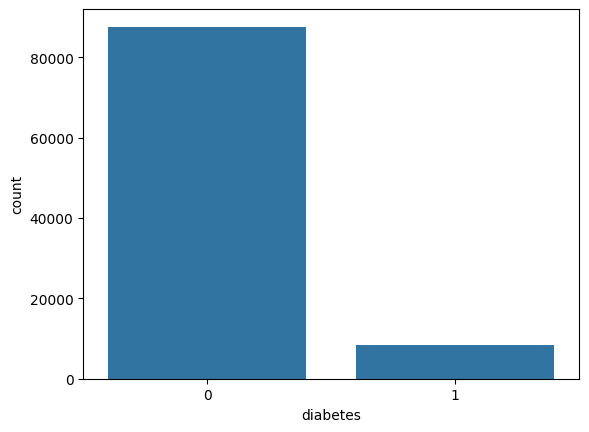

In [17]:
# TODO: sns.countplot(x='diabetes', data=df, color='tab:blue')
sns.countplot(x='diabetes', data=df, color='tab:blue')

Переглянути описові статистики **навчальної вибірки**

In [18]:
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE

In [19]:
# TODO: створіть X та y, де y — стовпець diabetes.
# TODO: поділіть X та y на train і test у пропорції 80/20.
# Використайте random_state=42 та stratify=y.

X = df.drop('diabetes', axis=1)
y = df['diabetes']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print('Train:', X_train.shape, 'Test:', X_test.shape)

Train: (76916, 8) Test: (19230, 8)


Закодувати категоріальні ознаки **після поділу**. Створюємо стовпці за категоріями з train; у test залишаємо точно такий самий набір стовпців.

In [20]:
# TODO: використайте pd.get_dummies для gender та smoking_history.
# TODO: закодуйте X_train та X_test.
# TODO: вирівняйте стовпці X_test за X_train через reindex(..., fill_value=0).

cat_cols = ['gender', 'smoking_history']
X_train = pd.get_dummies(X_train, columns=cat_cols, dtype=int)
X_test = pd.get_dummies(X_test, columns=cat_cols, dtype=int)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)
print('Ознак після кодування:', X_train.shape[1])

Ознак після кодування: 15


In [21]:
# TODO: виведіть статистики опису X_train.
X_train.describe()

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,gender_Female,gender_Male,gender_Other,smoking_history_No Info,smoking_history_current,smoking_history_ever,smoking_history_former,smoking_history_never,smoking_history_not current
count,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000
mean,41.760982,0.078007,0.040876,27.313739,5.530527,138.114281,0.582675,0.417143,0.000182,0.342022,0.095546,0.041175,0.097197,0.357650,0.066410
std,22.467762,0.268185,0.198004,6.757207,1.072421,40.896909,0.493121,0.493090,0.013490,0.474390,0.293969,0.198696,0.296228,0.479311,0.248999
min,0.080000,0.000000,0.000000,10.010000,3.500000,80.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,24.000000,0.000000,0.000000,23.390000,4.800000,100.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,43.000000,0.000000,0.000000,27.320000,5.800000,140.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,59.000000,0.000000,0.000000,29.850000,6.200000,159.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000
max,80.000000,1.000000,1.000000,95.220000,9.000000,300.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


Перевірити кореляцію ознак із цільовою змінною **лише на train**

In [22]:
# TODO: обчисліть кореляцію X_train із y_train (не використовуйте df або y_test).
X_train.corrwith(y_train).sort_values(ascending=False)

,0
blood_glucose_level,0.423011
HbA1c_level,0.405321
age,0.266649
bmi,0.213456
hypertension,0.199069
heart_disease,0.174470
smoking_history_former,0.096162
gender_Male,0.040650
smoking_history_never,0.025725
smoking_history_ever,0.020899


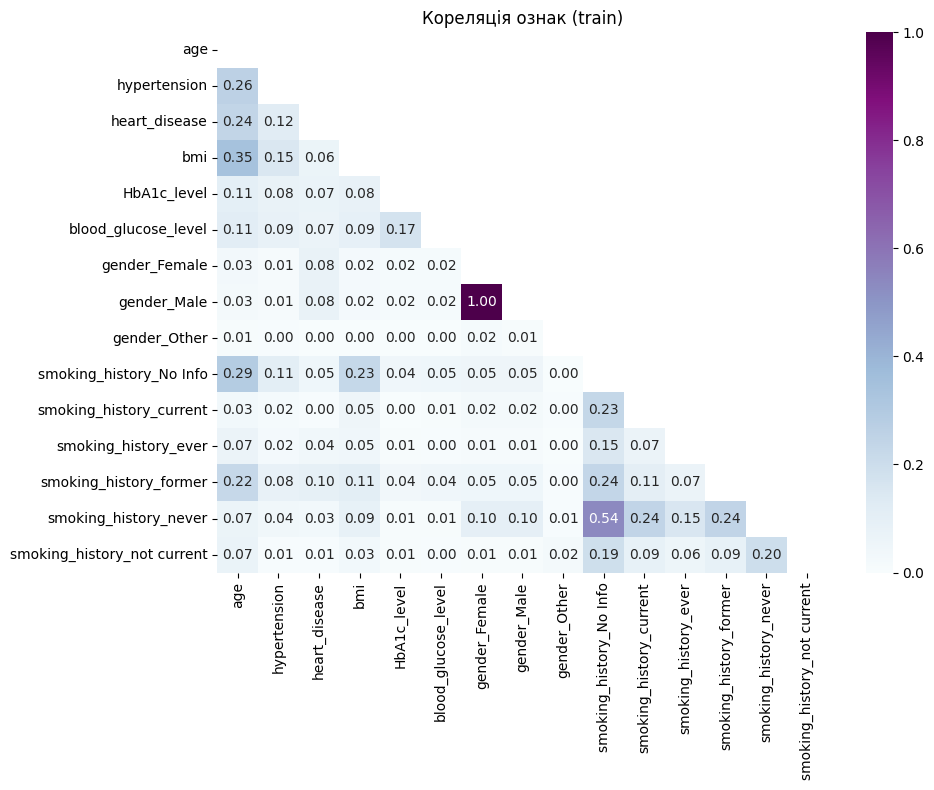

In [44]:
# TODO: обчисліть матрицю кореляції ознак X_train.
# TODO: побудуйте теплову карту (sns.heatmap).

mtx = X_train.corr(numeric_only=True).abs()

plt.figure(figsize=(10, 8))
sns.heatmap(mtx, cmap='BuPu', annot=True, fmt='.2f',
            mask=np.triu(np.ones_like(mtx, dtype=bool)),
            vmin=0, vmax=1)
plt.title('Кореляція ознак (train)')
plt.tight_layout()
plt.show()

**Висновок:** Найбільшу кореляцію з цільовою змінною diabetes мають blood_glucose_level (0,423), HbA1c_level (0,405), age (0,267) та bmi (0,213). Це свідчить про найбільший зв'язок показників глюкози та глікованого гемоглобіну з наявністю діабету. Між основними числовими ознаками сильних кореляцій не виявлено. Водночас спостерігається майже повна залежність між закодованими категоріями gender_Female та gender_Male, що пояснюється особливостями кодування. Видалення ознак на цьому етапі не є обов'язковим, оскільки вони можуть містити корисну інформацію для класифікації.

Перевірити викиди **лише на навчальній вибірці**

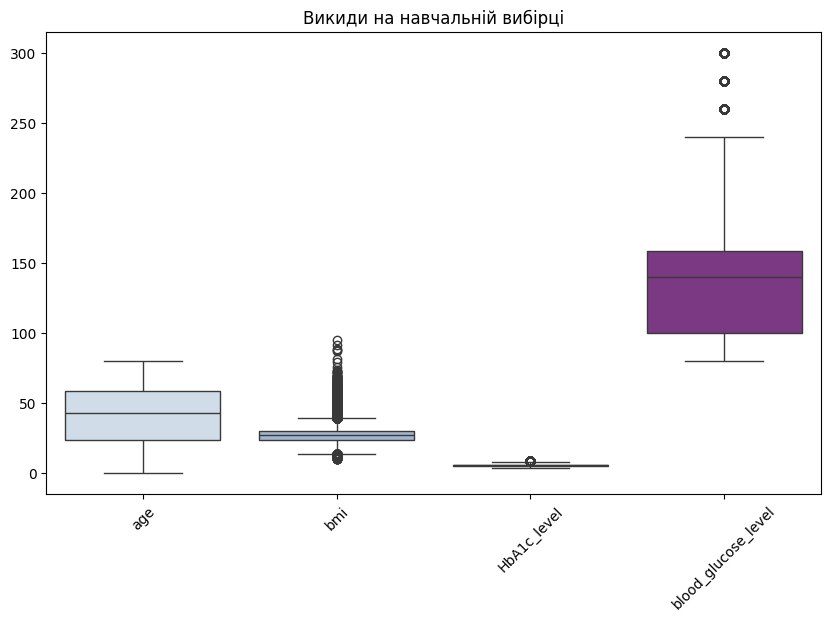

In [28]:
# TODO: задайте continuous_cols для age, bmi, HbA1c_level, blood_glucose_level.
# TODO: побудуйте boxplot за X_train[continuous_cols], НЕ за df.

continuous_cols = ['age', 'bmi', 'HbA1c_level', 'blood_glucose_level']

plt.figure(figsize=(10, 6))
sns.boxplot(data=X_train[continuous_cols], palette='BuPu')
plt.xticks(rotation=45)
plt.title('Викиди на навчальній вибірці')
plt.show()

**Висновок:** За результатами аналізу діаграм розмаху виявлено викиди переважно для показників bmi, HbA1c_level та blood_glucose_level. Вони відображають значення, що суттєво відрізняються від основної частини спостережень. Оскільки екстремальні значення медичних показників можуть бути клінічно важливими, автоматичне видалення викидів не проводилося. Усі записи залишено для подальшого навчання моделей.

**Необов’язковий приклад.** Якщо потрібно видалити викиди методом IQR, межі обчислюємо **тільки на train**, видаляємо відповідні рядки з `X_train` і `y_train`, а `X_test` та `y_test` не змінюємо. У цій роботі приклад не запускаємо.

In [ ]:
# НЕОБОВ'ЯЗКОВО: опишіть, як обчислити IQR для bmi тільки на X_train.
# Якщо вирішите вилучати рядки, синхронно оновіть X_train та y_train.
# Тестові дані не змінюйте. У цій роботі викиди не видаляємо.

# q1 = X_train['bmi'].quantile(0.25)
# q3 = X_train['bmi'].quantile(0.75)
# iqr = q3 - q1
# mask = X_train['bmi'].between(q1 - 1.5 * iqr, q3 + 1.5 * iqr)
# X_train = X_train.loc[mask].copy()
# y_train = y_train.loc[mask].copy()
# X_test і y_test залишаються без змін!

Перевірити асиметрію розподілів ознак **на train**

In [29]:
# TODO: знайдіть асиметрію розподілів X_train[continuous_cols].
X_train[continuous_cols].skew()

,0
age,-0.061461
bmi,1.005016
HbA1c_level,-0.055651
blood_glucose_level,0.830778


In [30]:
# TODO: перевірте пропуски окремо в X_train та X_test.
print('Пропуски train:', X_train.isnull().sum().sum())
print('Пропуски test:', X_test.isnull().sum().sum())

Пропуски train: 0
Пропуски test: 0


**Проміжний висновок:** Після видалення 3 854 дублікатів набір даних містить 96 146 записів, серед яких 87 664 належать до класу 0 та 8 482 — до класу 1. Кореляційний аналіз показав найбільший зв'язок із цільовою змінною для показників глюкози та глікованого гемоглобіну. Під час перевірки розподілів виявлено додатну асиметрію для bmi (1,005) та blood_glucose_level (0,831), а також наявність викидів. Пропущених значень у навчальній і тестовій вибірках не виявлено. Викиди не видалялися, а тестова вибірка не використовувалася для прийняття рішень щодо обробки даних.

Масштабуємо ознаки: `fit_transform` лише для train, `transform` — для test.

In [34]:
# TODO: створіть StandardScaler.
# TODO: виконайте fit_transform на X_train і transform на X_test.

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print('Масштабування завершено')
print('Train:', X_train_scaled.shape)
print('Test:', X_test_scaled.shape)

Масштабування завершено
Train: (76916, 15)
Test: (19230, 15)


Балансуємо лише навчальну вибірку за допомогою SMOTE

In [35]:
# TODO: збалансуйте тільки масштабовану навчальну вибірку методом SMOTE.
# TODO: порівняйте кількості класів до та після балансування.

smote = SMOTE(random_state=42)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train_scaled, y_train)

print('До балансування:')
print(y_train.value_counts())
print('\nПісля SMOTE:')
print(y_train_balanced.value_counts())

До балансування:
diabetes
0    70130
1     6786
Name: count, dtype: int64

Після SMOTE:
diabetes
0    70130
1    70130
Name: count, dtype: int64


Оголошуємо моделі

In [36]:
# TODO: створіть словник models для чотирьох моделей:
# LogisticRegression, RidgeClassifier, SGDClassifier, SVC.
# Для відтворюваності вкажіть random_state=42, де це передбачено.

models = {
    'LogisticRegression': LogisticRegression(max_iter=1000),
    'RidgeClassifier': RidgeClassifier(),
    'SGDClassifier': SGDClassifier(random_state=42),
    'SVC': SVC()
}

Навчити моделі, вивести матриці плутанини, класифікаційний звіт



=== LogisticRegression ===
              precision    recall  f1-score   support

           0       0.99      0.89      0.93     17534
           1       0.43      0.88      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230



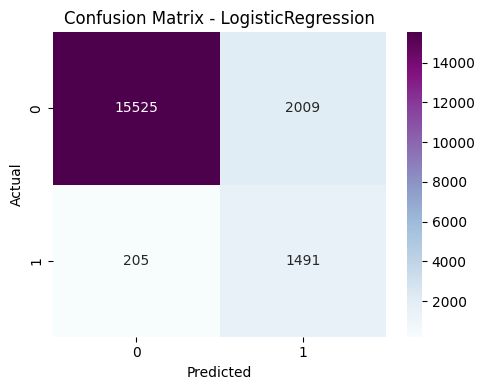


=== RidgeClassifier ===
              precision    recall  f1-score   support

           0       0.99      0.89      0.94     17534
           1       0.43      0.88      0.58      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.76     19230
weighted avg       0.94      0.89      0.90     19230



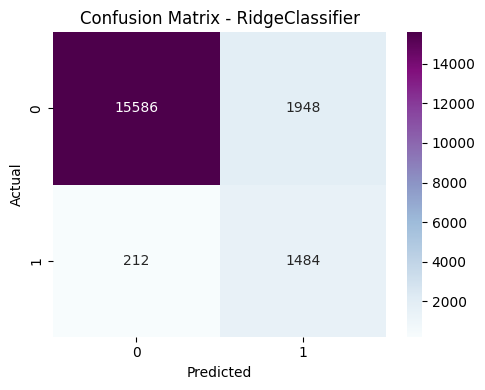


=== SGDClassifier ===
              precision    recall  f1-score   support

           0       0.99      0.86      0.92     17534
           1       0.38      0.91      0.54      1696

    accuracy                           0.86     19230
   macro avg       0.68      0.88      0.73     19230
weighted avg       0.94      0.86      0.88     19230



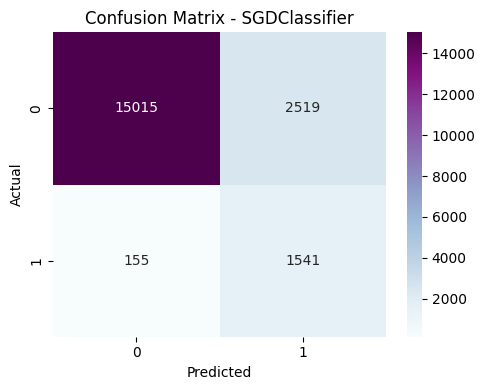


=== SVC ===
              precision    recall  f1-score   support

           0       0.99      0.88      0.93     17534
           1       0.43      0.91      0.58      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.89      0.76     19230
weighted avg       0.94      0.88      0.90     19230



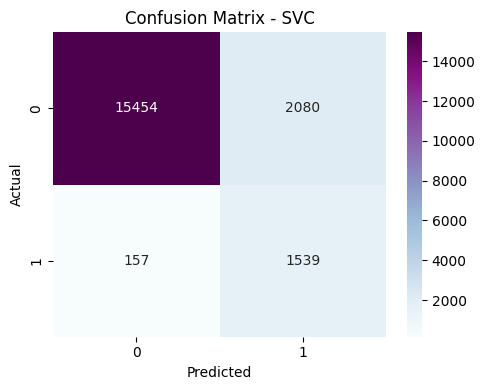

In [43]:
# TODO: навчіть кожну модель на збалансованій навчальній вибірці.
# TODO: зробіть прогноз на масштабованій X_test.
# TODO: виведіть classification_report та confusion_matrix (теплова карта).

for name, model in models.items():
    model.fit(X_train_balanced, y_train_balanced)
    predictions = model.predict(X_test_scaled)

    print(f"\n=== {name} ===")
    print(classification_report(y_test, predictions, zero_division=0))

    cm = confusion_matrix(y_test, predictions)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='BuPu')
    plt.title(f'Confusion Matrix - {name}')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.tight_layout()
    plt.show()

Оптимізувати гіперпараметри


In [38]:
# TODO: задайте словник param_grids для кожної моделі.
# Приклади: C та solver; alpha; loss та penalty; C та kernel.

param_grids = {
    'LogisticRegression': {
        'C': [0.01, 0.1, 1, 10],
        'solver': ['lbfgs', 'liblinear']
    },
    'RidgeClassifier': {
        'alpha': [0.1, 1.0, 10.0]
    },
    'SGDClassifier': {
        'loss': ['log_loss', 'hinge'],
        'alpha': [0.0001, 0.001, 0.01],
        'penalty': ['l2', 'l1']
    },
    'SVC': {
        'C': [0.1, 1, 10],
        'kernel': ['linear', 'rbf']
    }
}

Підбираємо параметри методом **HalvingGridSearchCV** із `cv=3`, `scoring="f1"`. Масштабування та SMOTE виконуються в кожному навчальному згині, щоб не було витоку даних. На малих порціях для пошуку задаємо достатній мінімальний розмір навчальних даних.

In [39]:
# Для HalvingGridSearchCV потрібен цей імпорт перед основним імпортом.
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingGridSearchCV
from imblearn.pipeline import Pipeline

In [40]:
# TODO: створіть best_models і best_scores.
# TODO: для кожної моделі визначте Pipeline: StandardScaler -> SMOTE -> модель.
# TODO: запустіть HalvingGridSearchCV із cv=3, scoring='f1', min_resources=300.
# TODO: шукайте параметри ТІЛЬКИ на X_train, y_train.
# TODO: виведіть оптимальні параметри та класифікаційний звіт.

best_models = {}
best_scores = {}

for name, model in models.items():
    print(f"\nПідбір параметрів для {name}...")

    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('smote', SMOTE(random_state=42)),
        ('model', model)
    ])

    params = {'model__' + key: values for key, values in param_grids[name].items()}

    search = HalvingGridSearchCV(
        pipeline, params, scoring='f1', cv=3, factor=2,
        min_resources=300, random_state=42, n_jobs=1
    )

    search.fit(X_train, y_train)

    best_models[name] = search.best_estimator_
    best_scores[name] = search.best_score_

    print('Найкращі параметри:', search.best_params_)
    print(f'F1 на кросвалідації: {search.best_score_:.3f}')

    predictions = search.best_estimator_.predict(X_test)
    print('Класифікаційний звіт на test:')
    print(classification_report(y_test, predictions, zero_division=0))


Підбір параметрів для LogisticRegression...
Найкращі параметри: {'model__C': 0.01, 'model__solver': 'lbfgs'}
F1 на кросвалідації: 0.653
Класифікаційний звіт на test:
              precision    recall  f1-score   support

           0       0.99      0.89      0.93     17534
           1       0.43      0.88      0.57      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.75     19230
weighted avg       0.94      0.89      0.90     19230


Підбір параметрів для RidgeClassifier...
Найкращі параметри: {'model__alpha': 10.0}
F1 на кросвалідації: 0.571
Класифікаційний звіт на test:
              precision    recall  f1-score   support

           0       0.99      0.89      0.94     17534
           1       0.43      0.88      0.58      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.76     19230
weighted avg       0.94      0.89      0.90     19230


Підбір параметрів для SGDClassifier.

Вибрати найкращу модель за середнім F1 на кросвалідації (а не за тестовою вибіркою)

In [41]:
# TODO: виберіть найкращу модель за середнім F1 на кросвалідації.
# Збережіть її в змінну best_model і виведіть назву та F1.

best_name = max(best_scores, key=best_scores.get)
best_model = best_models[best_name]
print(f'Найкраща модель: {best_name}, F1 = {best_scores[best_name]:.3f}')

Найкраща модель: LogisticRegression, F1 = 0.653


In [42]:
# TODO: виберіть 10 випадкових індексів тестової вибірки (random_state=42).
# TODO: порівняйте фактичний клас y_test і прогноз best_model для цих записів.
# Виведіть таблицю: індекс, істинний клас, передбачений клас.

random_indices = np.random.default_rng(42).choice(len(X_test), size=10, replace=False)
y_pred_best = best_model.predict(X_test.iloc[random_indices])

random_results_df = pd.DataFrame({
    'Index': X_test.iloc[random_indices].index,
    'True Values': y_test.iloc[random_indices].values,
    'Predicted Values': y_pred_best
})

random_results_df

,Index,True Values,Predicted Values
0,72555,0,1
1,42651,1,1
2,9181,0,0
3,67901,0,0
4,25253,0,0
5,58082,0,0
6,41116,0,1
7,63015,0,0
8,76480,0,0
9,15158,0,0


**Підсумкові висновки (заповніть самостійно):**

1. Який дисбаланс класів спостерігався? Що показали кореляція та перевірка викидів **на train**?
2. Які моделі дали кращі `F1` і `recall` для класу `diabetes = 1`? Яка модель обрана за кросвалідацією?
3. Які оптимальні гіперпараметри отримано? Які помилки видно в матриці плутанини?
4. Навіщо відкладати тестові дані та виконувати масштабування й SMOTE тільки на train?

**1.** У початковому наборі даних спостерігався значний дисбаланс класів: 91,5% записів належали до класу 0 та 8,5% — до класу 1. Після видалення дублікатів дисбаланс зберігся. Кореляційний аналіз показав найбільший зв'язок із наявністю діабету для blood_glucose_level (0,423) та HbA1c_level (0,405). Також було виявлено викиди серед числових показників, які вирішено не видаляти через їхню можливу клінічну значущість. Для усунення дисбалансу навчальної вибірки застосовано метод SMOTE, після якого кількість записів кожного класу становила 70 130.

**2.** Після початкового навчання найвищий F1 для класу diabetes = 1 отримали RidgeClassifier та SVC (0,58), а найбільший recall продемонстрували SGDClassifier і SVC (0,91). За результатами оптимізації гіперпараметрів найкращою моделлю стала LogisticRegression із середнім F1 на кросвалідації 0,653. На тестовій вибірці оптимізована модель показала F1 = 0,57 та recall = 0,88 для класу 1.

**3.** За результатами HalvingGridSearchCV отримано такі оптимальні параметри: для LogisticRegression — C = 0,01, solver = lbfgs; для RidgeClassifier — alpha = 10; для SGDClassifier — alpha = 0,01, loss = log_loss, penalty = l1; для SVC — C = 1, kernel = linear. Аналіз матриць плутанини показав, що моделі достатньо добре виявляють пацієнтів із діабетом, однак допускають значну кількість хибнопозитивних прогнозів. Наприклад, початкова LogisticRegression правильно визначила 1 491 випадок діабету, пропустила 205 випадків та помилково віднесла 2 009 пацієнтів без діабету до класу 1.

**4.** Відокремлення тестової вибірки дозволяє об'єктивніше оцінити здатність моделей працювати з новими даними. Масштабування StandardScaler виконується з визначенням параметрів лише на навчальній вибірці, після чого ці параметри застосовуються до тестової. Метод SMOTE також використовується тільки для навчальних даних, щоб усунути дисбаланс без спотворення тестової вибірки. Під час кросвалідації масштабування та балансування виконуються окремо в кожному навчальному згині, що запобігає витоку інформації та сприяє більш надійному оцінюванню моделей.

**Додаткове завдання.**

Реалізувати моделі **XGBoost, LightGBM та CatBoost.**

Вивести класифікаційний звіт та матрицю плутанини для кожної моделі.

Оцінити, зробити висновки про отримані метрики

In [45]:
!pip install -q xgboost lightgbm catboost

In [46]:
# Імпорт моделей
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# Імпорт метрик оцінювання
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

In [47]:
# Список для збереження результатів моделей
additional_results = []

# Функція навчання та оцінювання моделі
def evaluate_model(name, model):

    # Навчання на збалансованій вибірці
    model.fit(X_train_balanced, y_train_balanced)

    # Прогнозування на тестовій вибірці
    predictions = model.predict(X_test_scaled)

    # Класифікаційний звіт
    print(f'\n=== {name} ===')
    print(classification_report(y_test, predictions, zero_division=0))

    # Матриця плутанини
    cm = confusion_matrix(y_test, predictions)

    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='BuPu',
                xticklabels=[0, 1], yticklabels=[0, 1])

    plt.title(f'Confusion Matrix - {name}')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.tight_layout()
    plt.show()

    # Збереження метрик
    additional_results.append({
        'Модель': name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision (1)': precision_score(y_test, predictions, zero_division=0),
        'Recall (1)': recall_score(y_test, predictions, zero_division=0),
        'F1 (1)': f1_score(y_test, predictions, zero_division=0)
    })


=== XGBoost ===
              precision    recall  f1-score   support

           0       0.97      0.99      0.98     17534
           1       0.93      0.71      0.81      1696

    accuracy                           0.97     19230
   macro avg       0.95      0.85      0.90     19230
weighted avg       0.97      0.97      0.97     19230



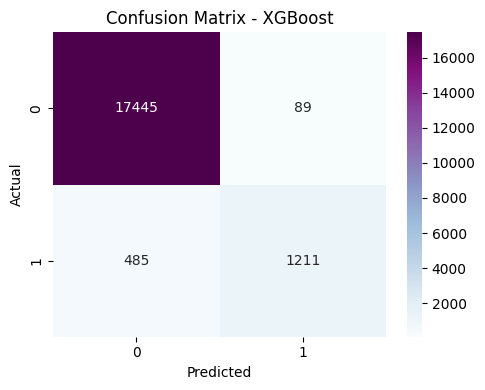

In [48]:
# Створення моделі XGBoost
xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.1,
    random_state=42,
    eval_metric='logloss',
    tree_method='hist'
)

# Навчання та оцінювання моделі
evaluate_model('XGBoost', xgb_model)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(



=== LightGBM ===
              precision    recall  f1-score   support

           0       0.97      1.00      0.98     17534
           1       0.94      0.70      0.80      1696

    accuracy                           0.97     19230
   macro avg       0.96      0.85      0.89     19230
weighted avg       0.97      0.97      0.97     19230



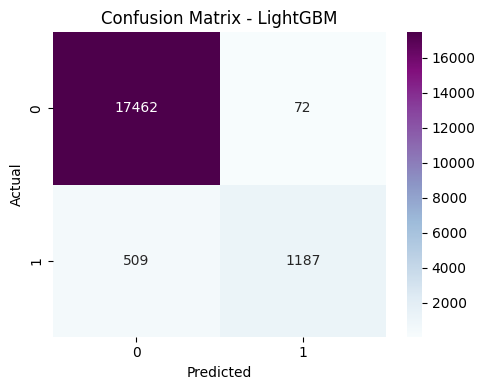

In [49]:
# Створення моделі LightGBM
lgbm_model = LGBMClassifier(
    n_estimators=200,
    learning_rate=0.1,
    random_state=42,
    verbosity=-1
)

# Навчання та оцінювання моделі
evaluate_model('LightGBM', lgbm_model)


=== CatBoost ===
              precision    recall  f1-score   support

           0       0.97      1.00      0.98     17534
           1       0.95      0.71      0.81      1696

    accuracy                           0.97     19230
   macro avg       0.96      0.85      0.90     19230
weighted avg       0.97      0.97      0.97     19230



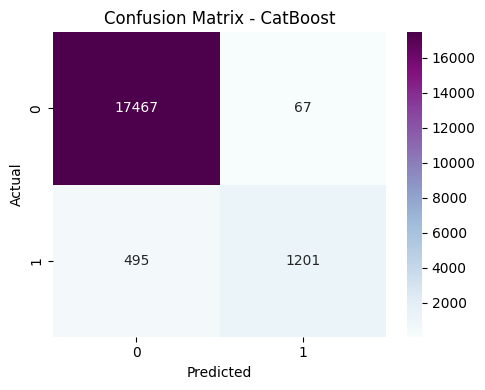

In [50]:
# Створення моделі CatBoost
catboost_model = CatBoostClassifier(
    iterations=200,
    depth=6,
    learning_rate=0.1,
    random_seed=42,
    verbose=False,
    allow_writing_files=False
)

# Навчання та оцінювання моделі
evaluate_model('CatBoost', catboost_model)

In [51]:
# Створення таблиці порівняння моделей
results_df = pd.DataFrame(additional_results)

# Сортування за F1-score для класу 1
results_df = results_df.sort_values(
    by='F1 (1)',
    ascending=False
)

# Виведення результатів
print('Порівняння результатів моделей:')
display(results_df.round(3))

# Визначення найкращої моделі
best_additional = results_df.iloc[0]

print(f"\nНайкраща модель: {best_additional['Модель']}")
print(f"F1-score: {best_additional['F1 (1)']:.3f}")

Порівняння результатів моделей:


,Модель,Accuracy,Precision (1),Recall (1),F1 (1)
2,CatBoost,0.971,0.947,0.708,0.810
0,XGBoost,0.970,0.932,0.714,0.808
1,LightGBM,0.970,0.943,0.700,0.803



Найкраща модель: CatBoost
F1-score: 0.810


**Висновок**

У ході виконання додаткового завдання було реалізовано та навчено три моделі класифікації: XGBoost, LightGBM та CatBoost. Для оцінювання їхньої ефективності використано класифікаційні звіти, матриці плутанини та основні метрики якості.

Усі три моделі продемонстрували високу загальну точність класифікації (97%). Найкращий результат за F1-score для класу 1 отримала модель CatBoost (0,810), яка також має найвищий precision (0,947). Модель XGBoost показала найбільший recall (0,714), а LightGBM отримала F1-score 0,803.

Аналіз матриць плутанини показав, що моделі добре розпізнають пацієнтів без діабету та допускають відносно невелику кількість хибнопозитивних прогнозів. Водночас приблизно 29–30% випадків діабету залишаються невиявленими. Порівняно з моделями основного завдання, алгоритми градієнтного бустингу забезпечили вищі precision та F1-score на тестовій вибірці, проте продемонстрували нижчий recall для класу 1.

Отже, за результатами тестування найкращою серед додаткових моделей стала CatBoost. Однак для задач медичної діагностики важливо враховувати не лише загальну точність і F1-score, а й здатність моделі виявляти якомога більше випадків захворювання.